In [2]:
from rdkit import Chem
import os
from rdkit.Chem.Draw import IPythonConsole
ptable = Chem.GetPeriodicTable()
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}


In [3]:
"""
Rule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks
Rule 2: Identify suitable leaving groups (suitable sigma star)
Rule 2.5: Identify reactive sigma bonds
Rule 3: Identify acidic hydrogens
"""

'\nRule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks\nRule 2: Identify suitable leaving groups (suitable sigma star)\nRule 2.5: Identify reactive sigma bonds\nRule 3: Identify acidic hydrogens\n'

In [4]:
cat_and_brom = Chem.MolFromSmiles(r'C[C+](C)C.[Br-]')
tert_brom = Chem.MolFromSmiles('CC(C)(Br)C')

In [5]:
def identify_source(mol, rules = "all"):
    for atom in mol.GetAtoms():
        # Look for hydrides - M-H bond
        if electronegativity_dict[atom.GetAtomicNum()] < 2.05 and atom.GetFormalCharge() < 0 and atom.GetNumExplicitHs() > 0:
            atom.SetProp('source', 'hydride')
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        if lone_electrons > 0:
            atom.SetProp('source', 'lone pair')
            
    for bond in mol.GetBonds():
        if bond.GetEndAtom().HasProp('source') or bond.GetBeginAtom().HasProp('source'):
            continue
        # Conditional on rules being on
        if rules == 'all':
            if bond.GetBondTypeAsDouble() == 1:
                # For any element less electronegative than boron (inclusive) - add sigma bond as source - going from more electronegative atom
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] < 2.05:
                    #bond.GetEndAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
                    bond.SetProp('source_bond_atom', str(bond.GetEndAtom().GetIdx()))
                    bond.SetProp('source_other_atom', str(bond.GetBeginAtom().GetIdx()))
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] < 2.05:
                    #bond.GetBeginAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
                    bond.SetProp('source_bond_atom', str(bond.GetBeginAtom().GetIdx()))
                    bond.SetProp('source_other_atom', str(bond.GetEndAtom().GetIdx()))
        # Looking for double and triple bonds - ignoring aromatic systems
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('source', 'pi bond')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            # if bond is homonuclear then either atom can be source
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                #atom1.SetProp('source', 'pi bond')
                #atom2.SetProp('source', 'pi bond')
                bond.SetProp('source_bond_atom', 'both')
                bond.SetProp('source_other_atom', 'both')
            else:
                # if bond is heteronuclear then the more electronegative atom is source
                if electronegativity_dict[atom1.GetAtomicNum()] < electronegativity_dict[atom2.GetAtomicNum()]:
                    bond.SetProp('source_bond_atom', str(atom2.GetIdx()))
                    bond.SetProp('source_other_atom', str(atom1.GetIdx()))
                else:
                    bond.SetProp('source_bond_atom', str(atom1.GetIdx()))
                    bond.SetProp('source_other_atom', str(atom2.GetIdx()))
    # This loop coming after the bond loop ensures that all molecules with lone pairs react via the lone pair instead of a pi bond
    
        
        

In [6]:
def identify_sink(mol, rules = "all"):
    for atom in mol.GetAtoms():
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        num_bond_electrons = atom.GetTotalValence()*2
        # this may only be valid for the first few rows of the periodic table
        if lone_electrons + num_bond_electrons < 8 and valence_electrons > 2:
            atom.SetProp('sink', 'empty AO')
        #Special case for H not needed any more I think?
        if atom.GetAtomicNum() == 1 and lone_electrons + num_bond_electrons < 2:
            atom.SetProp('sink', 'empty AO')

    for bond in mol.GetBonds():
        if bond.GetEndAtom().HasProp('sink') or bond.GetBeginAtom().HasProp('sink'):
            continue
        # Conditional on all rules being swtiched on
        if rules == "all":
            # Identify possible sigma stars by considering leaving groups being any element that has a higher electronegativity than carbon
            if bond.GetBondTypeAsDouble() == 1:
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    #Set the other atom connected to this leaving group as the electron sink
                    #bond.GetBeginAtom().SetProp('sink', 'sigma star')
                    bond.SetProp('sink_bond_atom', str(bond.GetBeginAtom().GetIdx()))
                    bond.SetProp('sink_other_atom', str(bond.GetEndAtom().GetIdx()))
                # Repeat for the other atom in a bond. Note e.g. N-N would be possible to attack at each end
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    #bond.GetEndAtom().SetProp('sink', 'sigma star')
                    #bond.GetEndAtom().SetProp('sink', 'sigma star')
                    bond.SetProp('sink_bond_atom', str(bond.GetEndAtom().GetIdx()))
                    bond.SetProp('sink_other_atom', str(bond.GetBeginAtom().GetIdx()))
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('sink', 'pi star')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                #atom1.SetProp('sink', 'pi star')
                #atom2.SetProp('sink', 'pi star')
                bond.SetProp('sink_bond_atom', 'both')
                bond.SetProp('sink_other_atom', 'both')
            else:
                if electronegativity_dict[atom1.GetAtomicNum()] > electronegativity_dict[atom2.GetAtomicNum()]:
                    bond.SetProp('sink_bond_atom', str(atom2.GetIdx()))
                    bond.SetProp('sink_other_atom', str(atom1.GetIdx()))
                else:
                    #atom1.SetProp('sink', 'pi star')
                    bond.SetProp('sink_bond_atom', str(atom1.GetIdx()))
                    bond.SetProp('sink_other_atom', str(atom2.GetIdx()))
    # Likewise as above, this loop coming second ensures that empty orbitals are attacked in place of a pi star where an atom might have both
    

In [7]:
def prepare_molecule(mol):
    identify_sink(mol)
    identify_source(mol)
    return None

In [8]:
acetophenone = Chem.MolFromSmiles('CC(=O)C1=CC=CC=C1')
cyanide = Chem.MolFromSmiles('[C-]#N')
ethylbromide = Chem.MolFromSmiles('CCBr')
iodide = Chem.MolFromSmiles('[I-]')

In [9]:
identify_sink(cyanide)
identify_source(cyanide)
identify_sink(ethylbromide)
identify_source(acetophenone)

In [10]:
def b_to_a(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    bond_order = int(bond.GetBondTypeAsDouble())
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    if bond_order != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order-1])
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

In [11]:
def clean_mol(list_mol):
    existing_inchi = set([])
    clean_list = []
    for mol in list_mol:
        inchi = Chem.MolToInchi(mol)
        if inchi not in existing_inchi:
            existing_inchi.add(inchi)
            clean_list.append(mol)
    return clean_list

In [33]:
mol2 = Chem.MolFromSmiles('OOC(=O)C1=CC=CC=C1')
mol1 = Chem.MolFromSmiles('C=C')
prepare_molecule(mol1)
prepare_molecule(mol2)
new_mols = []
connected_mols = []
atoms = [a for a in mol1.GetAtoms()] + [a for a in mol2.GetAtoms()]
bonds = [b for b in mol1.GetBonds()] + [b for b in mol2.GetBonds()]
for atom1 in atoms:
    loop_number = 0
    
    while loop_number < 3:
        #print(loop_number)

        if loop_number == 1:
            loop_number = 2
            source_type = atom1.GetProp('source')
            atom1.ClearProp('source')
            atom1.SetProp('sink', sink_type)

        elif atom1.HasProp('source') and atom1.HasProp('sink'):
            loop_number = 1
            sink_type = atom1.GetProp('sink')
            atom1.ClearProp('sink')

        if atom1.HasProp('source'):
            print(atom1.GetIdx(), atom1.GetSymbol(), atom1.GetTotalValence(), atom1.GetProp('source'))            
            if atom1.GetProp('source') == 'lone pair' or atom1.GetProp('source') == 'hydride':
                atom1.SetBoolProp('make_bond', 1)
                for atom2 in atoms:
                    if atom1.GetOwningMol()== atom2.GetOwningMol and atom1.GetIdx() == atom2.GetIdx():
                        continue
                    if atom2.HasProp('sink'):
                        print(atom2.GetIdx(), atom2.GetSymbol(), atom2.GetTotalValence(), atom2.GetProp('sink'))
                        if atom2.GetProp('sink') == 'empty AO':
                            atom2.SetBoolProp('make_bond', 1)
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                        atom2.ClearProp('make_bond')
                
                for bond2 in bonds:
                    clear_prop = False
                    if bond2.HasProp('sink'):
                        if bond2.HasProp('source'):
                            bond2_source = bond2.GetProp('source')
                            bond2.ClearProp('source')
                            clear_prop = True
                        print('sink', bond2.GetProp('sink'))
                        bond2.SetBoolProp('make_bond', 1)
                        a1 = bond2.GetBeginAtom()
                        a2 = bond2.GetEndAtom()
                        print('sink', bond2.GetProp('sink_bond_atom'))
                        #print('other', bond2.GetProp('other_bond_atom'))
                        print(a1.GetSymbol(), a1.GetIdx(), a2.GetSymbol(), a2.GetIdx())
                        if bond2.GetProp('sink_bond_atom') == 'both':
                            a1.SetBoolProp('make_bond', 1)
                            a2.SetBoolProp('other_atom', 1)
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                            a1.ClearProp('make_bond')
                            a2.ClearProp('other_atom')
                            a2.SetBoolProp('make_bond', 1)
                            a1.SetBoolProp('other_atom', 1)
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                            a2.ClearProp('make_bond')
                            a1.ClearProp('other_atom')
                        if bond2.GetProp('sink_bond_atom') == str(a1.GetIdx()):
                            print('if statement 2')
                            print('a1', a1.GetSymbol(), 'a2', a2.GetSymbol())
                            print('atom1', atom1.GetSymbol(), atom1.GetProp('source'))
                            a1.SetBoolProp('make_bond', 1)
                            a2.SetBoolProp('other_atom', 1)
                            print('make_bond', a1.GetSymbol())
                            print('other_atom', a2.GetSymbol())
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                            a1.ClearProp('make_bond')
                            a2.ClearProp('other_atom')
                        elif bond2.GetProp('sink_bond_atom') == str(a2.GetIdx()):
                            print('if statement 3')
                            print('a1', a1.GetSymbol(), 'a2', a2.GetSymbol())
                            a2.SetBoolProp('make_bond', 1)
                            a1.SetBoolProp('other_atom', 1)
                            print('make_bond', a2.GetSymbol())
                            print('other_atom', a1.GetSymbol())
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                            a1.ClearProp('other_atom')
                            a2.ClearProp('make_bond')
                        bond2.ClearProp('make_bond')
                        if clear_prop:
                            bond2.SetProp('source', bond2_source)
            atom1.ClearProp('make_bond')
        if loop_number == 2:
            atom1.SetProp('source', source_type)
            break
        if loop_number == 0:
            break

        


for bond1 in bonds:
    has_sink = False
    loop_twice = False
    loop_once = True
    if bond1.HasProp('sink'):
        memory = bond1.GetProp('sink')
        bond1.ClearProp('sink')
        has_sink = True

    if bond1.HasProp('source'):
        print('source', bond1.GetProp('source'))
        bond1.SetBoolProp('make_bond', 1)
        a1 = bond1.GetBeginAtom()
        a2 = bond1.GetEndAtom()
        if bond1.GetProp('source_bond_atom') == 'both':
            a1.SetBoolProp('make_bond', 1)
            a2.SetBoolProp('other_atom', 1)
            loop_twice = True

        if bond1.GetProp('source_bond_atom') == str(a1.GetIdx()):
            a1.SetBoolProp('make_bond', 1)
            a2.SetBoolProp('other_atom', 1)
        elif bond1.GetProp('source_bond_atom') == str(a2.GetIdx()):
            a2.SetBoolProp('make_bond', 1)
            a1.SetBoolProp('other_atom', 1)
        print('check', a1.GetSymbol(), 'make bond?', a1.HasProp('make_bond'), a2.GetSymbol(), 'make bond?', a2.HasProp('make_bond'))
        while loop_once:
            for atom2 in atoms:
                if atom2.HasProp('sink'):
                    atom2.SetBoolProp('make_bond', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                    atom2.ClearProp('make_bond')
            for bond2 in bonds:
                if bond2.GetOwningMol()== bond1.GetOwningMol() and bond2.GetIdx() == bond1.GetIdx():
                    continue
                if bond2.HasProp('sink'):
                    bond2.SetBoolProp('make_bond', 1)
                    a3 = bond2.GetBeginAtom()
                    a4 = bond2.GetEndAtom()
                    if bond2.GetProp('sink_bond_atom') == 'both':
                        a3.SetBoolProp('make_bond', 1)
                        a4.SetBoolProp('other_atom', 1)
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a3.ClearProp('make_bond')
                        a4.ClearProp('other_atom')
                        a4.SetBoolProp('make_bond', 1)
                        a3.SetBoolProp('other_atom', 1)
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a4.ClearProp('make_bond')
                        a3.ClearProp('other_atom')
                    if bond2.GetProp('sink_bond_atom') == str(a3.GetIdx()):
                        print('if statement 2')
                        print('a3', a3.GetSymbol(), 'a4', a4.GetSymbol())
                        a3.SetBoolProp('make_bond', 1)
                        a4.SetBoolProp('other_atom', 1)
                        print('check', a3.GetSymbol(), 'make bond?', a3.HasProp('make_bond'), a4.GetSymbol(), 'make bond?', a4.HasProp('make_bond'))
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a3.ClearProp('make_bond')
                        a4.ClearProp('other_atom')
                    elif bond2.GetProp('sink_bond_atom') == str(a4.GetIdx()):
                        print('if statement 3')
                        print('a3', a3.GetSymbol(), 'a4', a4.GetSymbol())
                        a4.SetBoolProp('make_bond', 1)
                        a3.SetBoolProp('other_atom', 1)
                        print('check', a3.GetSymbol(), 'make bond?', a3.HasProp('make_bond'), a4.GetSymbol(), 'make bond?', a4.HasProp('make_bond'))
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a3.ClearProp('other_atom')
                        a4.ClearProp('make_bond')
                    bond2.ClearProp('make_bond')
            for a in [a1,a2]:
                if a.HasProp('make_bond'):
                    a.ClearProp('make_bond')
                if a.HasProp('other_atom'):
                    a.ClearProp('other_atom')
            if loop_twice:
                a2.SetBoolProp('make_bond', 1)
                a1.SetBoolProp('other_atom', 1)
                loop_twice = False
            else:
                break
        
    if has_sink:
        bond1.SetProp('sink', memory)
    bond1.ClearProp('make_bond')
   



0 O 2 lone pair
sink pi star
sink both
C 0 C 1
sink sigma star
sink 1
O 0 O 1
if statement 3
a1 O a2 O
make_bond O
other_atom O
sink sigma star
sink 2
O 1 C 2
if statement 3
a1 O a2 C
make_bond C
other_atom O
sink pi star
sink 2
C 2 O 3
if statement 2
a1 C a2 O
atom1 O lone pair
make_bond C
other_atom O
1 O 2 lone pair
sink pi star
sink both
C 0 C 1
sink sigma star
sink 1
O 0 O 1
if statement 3
a1 O a2 O
make_bond O
other_atom O
sink sigma star
sink 2
O 1 C 2
if statement 3
a1 O a2 C
make_bond C
other_atom O
sink pi star
sink 2
C 2 O 3
if statement 2
a1 C a2 O
atom1 O lone pair
make_bond C
other_atom O
3 O 2 lone pair
sink pi star
sink both
C 0 C 1
sink sigma star
sink 1
O 0 O 1
if statement 3
a1 O a2 O
make_bond O
other_atom O
sink sigma star
sink 2
O 1 C 2
if statement 3
a1 O a2 C
make_bond C
other_atom O
sink pi star
sink 2
C 2 O 3
if statement 2
a1 C a2 O
atom1 O lone pair
make_bond C
other_atom O
source pi bond
check C make bond? 1 C make bond? 0
if statement 3
a3 O a4 O
check O m

In [34]:
debug_mol = []
for mol in new_mols:
    inter_mol = mol
    k = None
    l = None
    # Need to treat hydrides differently because of the way RDKit handles them
    hydride_flag = False
    skip = False
    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond'):
            print('make bond has:', atom.GetSymbol())
            if atom.HasProp('source'):
                print('debug', atom.GetSymbol(), atom.GetProp('source'))
            if atom.HasProp('other_atom'):
                print('debug', atom.GetSymbol(), atom.GetProp('other_atom'))

    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond') and atom.HasProp('other_atom'):
            print('this condition is satisfied')
            skip = True
    
    if skip:
        continue

    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond'):
            if atom.HasProp('source'):
                print('source connecting loop', atom.GetSymbol(), atom.GetProp('source'))
                i = atom.GetIdx()
                # Different behaviour required for hydrides
                if atom.GetProp('source') == 'hydride':
                    hydride_flag = True
                    atom.SetNumExplicitHs(atom.GetNumExplicitHs() - 1)
                    atom.SetFormalCharge(atom.GetFormalCharge() + 1)
                    print(Chem.MolToSmiles(inter_mol))
            elif atom.HasProp('sink'):
                print('sink connecting loop', atom.GetSymbol(), atom.GetProp('sink'))
                j = atom.GetIdx()
            else:
                for bond in atom.GetBonds():
                    if bond.HasProp('make_bond'):
                        if bond.HasProp('source'):
                            print('source',bond.GetProp('source'))
                            for a in [bond.GetBeginAtom(), bond.GetEndAtom()]:
                                if a.HasProp('make_bond'):
                                    if a.HasProp('sink'):
                                        skip = True
                                        print('are we skipping?')
                                    i = a.GetIdx()
                                if a.HasProp('other_atom'):
                                    k = a.GetIdx()
                            if skip:
                                continue
                            print('i', inter_mol.GetAtomWithIdx(i).GetSymbol())
                            print('k', inter_mol.GetAtomWithIdx(k).GetSymbol())
                            inter_mol = b_to_a(inter_mol, k, i)
                        if bond.HasProp('sink'):
                            print('sink',bond.GetProp('sink'), bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol())
                            for a in [bond.GetBeginAtom(), bond.GetEndAtom()]:
                                if a.HasProp('make_bond'):
                                    if a.HasProp('source') or a.HasProp('source_other_atom'):
                                        print('we will skip')
                                        skip = True
                                    j = a.GetIdx()
                                if a.HasProp('other_atom'):
                                    l = a.GetIdx()
                            if skip:
                                continue
                            print('j', inter_mol.GetAtomWithIdx(j).GetSymbol())
                            print('l', inter_mol.GetAtomWithIdx(l).GetSymbol())
                            inter_mol = b_to_a(inter_mol, j, l)
                            debug_mol.append(inter_mol)
    if skip:
        continue                       
    if (k is not None and k == j) or (l is not None and l == i) or i == j:
        # this is will remove any 'cycles' that close in on themselves and make no net change
        continue
    if hydride_flag:
        print('here')
        inter_mol.GetAtomWithIdx(j).SetNumExplicitHs(inter_mol.GetAtomWithIdx(j).GetNumImplicitHs() + 1)
        inter_mol.GetAtomWithIdx(j).SetFormalCharge(inter_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
        connected_mols.append(inter_mol)
        continue
    print('making bond between', inter_mol.GetAtomWithIdx(i).GetSymbol(), i, inter_mol.GetAtomWithIdx(j).GetSymbol(), j)
    inter_mol = a_to_b(inter_mol, i, j)
    connected_mols.append(inter_mol)
    
# as it stands this doesn't work for Grignards because of the way that InChI is generated
connected_mols = clean_mol(connected_mols)
    


make bond has: C
make bond has: O
debug O lone pair
sink pi star C C
a C 0
j C
l C
source connecting loop O lone pair
making bond between O 2 C 0
make bond has: C
make bond has: O
debug O lone pair
sink pi star C C
a C 0
j C
l C
source connecting loop O lone pair
making bond between O 2 C 1
make bond has: O
debug O lone pair
debug O 1
make bond has: O
debug O lone pair
this condition is satisfied
make bond has: O
debug O lone pair
make bond has: C
source connecting loop O lone pair
sink sigma star O C
a C 0
j C
l O
making bond between O 2 C 4
make bond has: O
debug O lone pair
make bond has: C
source connecting loop O lone pair
sink pi star C O
a C 0
j C
l O
making bond between O 2 C 4
make bond has: C
make bond has: O
debug O lone pair
sink pi star C C
a C 0
j C
l C
source connecting loop O lone pair
making bond between O 3 C 0
make bond has: C
make bond has: O
debug O lone pair
sink pi star C C
a C 0
j C
l C
source connecting loop O lone pair
making bond between O 3 C 1
make bond has

In [35]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True


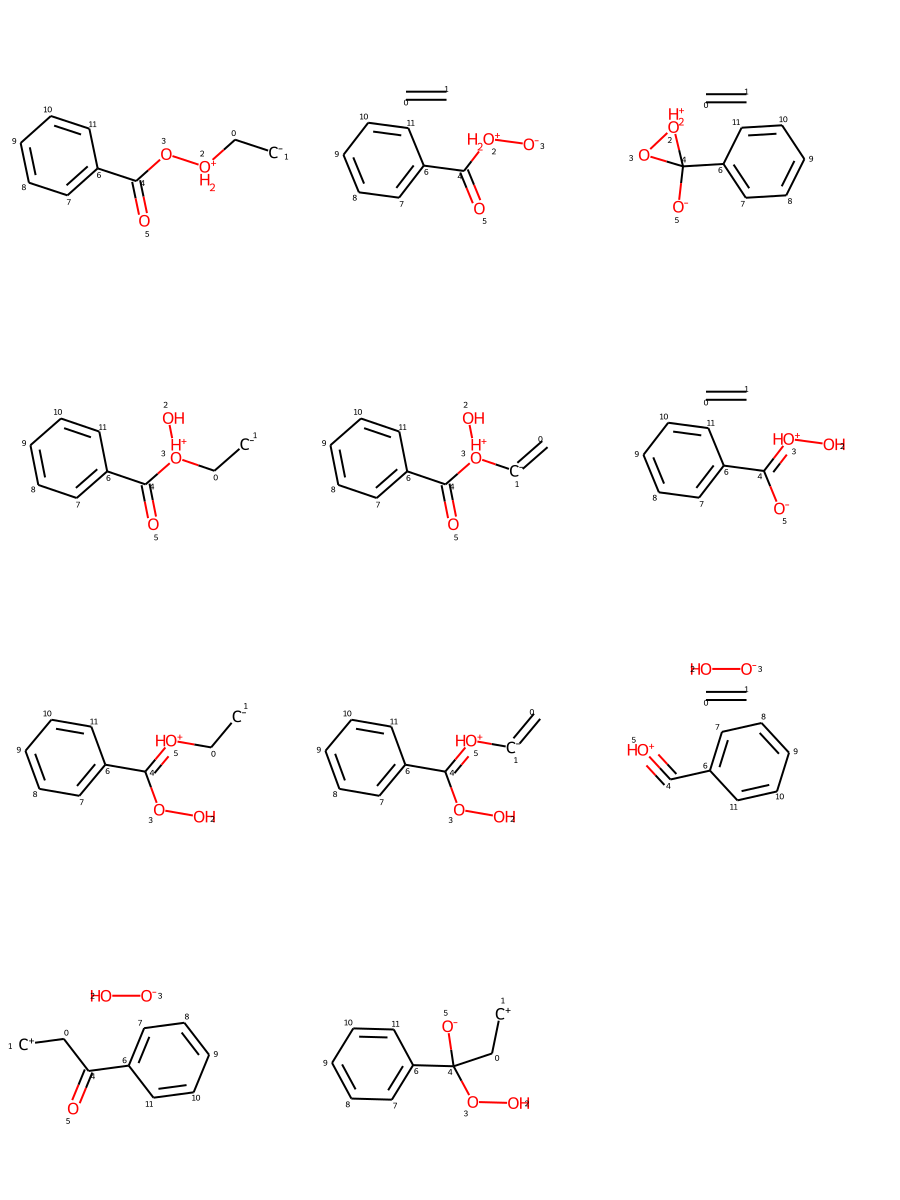

In [36]:
Chem.Draw.MolsToGridImage(connected_mols, molsPerRow=3, subImgSize=(300, 300))


In [77]:
for mol in connected_mols:
    print(Chem.MolToSmiles(mol))

In [169]:
Chem.MolToSmiles(connected_mols[0])

'CC(C)[O-].[BH4-].[Li+]'

In [44]:
for mol in new_mols:
    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond'):
            print('make bond has:', atom.GetSymbol())
            #if atom.HasProp('source'):
                #print('debug', atom.GetSymbol(), atom.GetProp('source'))
            #if atom.HasProp('other_atom'):
                #print('debug', atom.GetSymbol(), atom.GetProp('other_atom'))
    for bond in mol.GetBonds():
        if bond.HasProp('make_bond'):
            print('bond', bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol())
    print("-----------")

make bond has: C
make bond has: Br
bond C C
-----------
make bond has: C
make bond has: Br
bond C C
-----------


In [170]:
def write_reaction_smiles(mol1, mol2, product):
    with open ("reactions.txt", 'a', encoding='utf-8') as file:
        line = Chem.MolToSmiles(mol1) + "." + Chem.MolToSmiles(mol2) + ">>" + Chem.MolToSmiles(product)
        file.write(line +"\n")
    

In [111]:
for product in connected_mols:
    write_reaction_smiles(mol1, mol2, product)

In [17]:
Chem.MolToSmiles(inter_mol)

'C=C.[Br-].[BrH2+]'

In [24]:
m = Chem.MolFromSmiles('[BH4-]')

In [29]:
for a in m.GetAtoms():
    print(a.GetSymbol())
    print(a.GetNumExplicitHs())
    a.SetNumExplicitHs(a.GetNumExplicitHs() - 1)
    a.SetFormalCharge(a.GetFormalCharge() + 1)

B
4


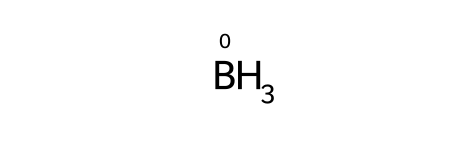

In [30]:
m